# Workings on Goal 1.2 and Explanation 2.2
The goal is to train a Random Forest model for the prediction of attrition of an employee.  
**Evaluate** the model, **explain** the approach and results

## How does Random Forest work?
We train multiple decision trees, each on a random feature-/ and employee-subset.  
For a prediction each tree gives a probability of leaving. The forest averages them.

### Why?
- Handles the mixed numeric features (e.g. MonthlyIncome) and one-hot-encoded (e.g. Department) features without scaling.
- Compared it to Logistic Regression and they had similar performance (slightly better for logistic regression) but we used Random Forest because of it's **black-box** nature that fits the SHAP task.

# Data Preparation

In [184]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    TunedThresholdClassifierCV,
    train_test_split,
)


In [185]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
employees_all_one = df["EmployeeCount"].eq(1).all()
print(f"Is Every EmployeeCount 1? {"Yes" if employees_all_one else "No"}")

# drop columns that are constants or noise (e.g. EmployeeNumber)
df = df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])

# transform strings into integers that can be fed in to sklearn
df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
df["OverTime"] = (df["OverTime"] == "Yes").astype(int)
df["Gender"] = (df["Gender"] == "Male").astype(int)

# transform travel frequency to integer using natural order
df["BusinessTravel"] = df["BusinessTravel"].map(
    {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
)

# one-hot encode other string values
df = pd.get_dummies(
    df, columns=["Department", "EducationField", "JobRole", "MaritalStatus"], dtype=int
)

df.head()

Is Every EmployeeCount 1? Yes


,Age,Attrition,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single
0,41,1,1,1102,1,2,2,0,94,3,...,0,0,0,0,0,1,0,0,0,1
1,49,0,2,279,8,1,3,1,61,2,...,0,0,0,0,1,0,0,0,1,0
2,37,1,1,1373,2,2,4,1,92,2,...,1,0,0,0,0,0,0,0,0,1
3,33,0,2,1392,3,4,4,0,56,3,...,0,0,0,0,1,0,0,0,1,0
4,27,0,1,591,2,1,1,1,40,3,...,1,0,0,0,0,0,0,0,1,0


# Train Test Split
We use 80/20 split and stratified sampling to force the attrition rate to also be 16% in the splits.  
Without it the split is random and could skew training or testing.

In [186]:
X = df.drop(columns="Attrition")
y = df["Attrition"]
SEED = 67
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(
    f"train: {len(y_train)} employees, {y_train.sum()} leavers ({y_train.mean():.1%}) | "
    f"test: {len(y_test)} employees, {y_test.sum()} leavers ({y_test.mean():.1%})"
)

train: 1176 employees, 190 leavers (16.2%) | test: 294 employees, 47 leavers (16.0%)


# Hyperparameters
We use a Parameter Grid to compare parameter combinations.  
This works by scoring each config on small validation set from the training set (can't use test set since would influence choice).  

Scoring is done with `average_precision` to choose the params whose risk ranking is best, meaning actual leavers get the highest risk scores. The measure focuses on the leavers since we don't want to inflate the measure when we rank one of the 84% stayers correctly.

Each round trains on `4` folds and scores on `1` validation fold. The folds are rotated through the 5 rounds.

`Stratified` because we want to keep the 16% attrition rate and not randomly have more leavers in some folds.  
`Repeated` because we don't want one shuffle to decide the 5 folds. Run the Stratified K-Fold 3 times to get different shuffles.

### Scoring process
```
repeat 1: shuffle A → 5 folds → 5 scores
repeat 2: shuffle B → 5 folds → 5 scores
repeat 3: shuffle C → 5 folds → 5 scores
                                mean of 15 scores
```

## Fixed Parameters
- `n_estimators`: the number of trees used internally, set to a high value like 500.  
- `max_features`: use the default scikit `sqrt`

The imbalance of leavers vs stayers is handled in the next step (Threshold Choosing).

## Searched Parameters
`min_samples_leaf`: the minimum number of training employees that must end up in each leaf. Too small => overfitting (a leaf remembers single employees). Too large => underfitting (real differences between groups are averaged away).  
`criterion`: measures quality of a split (diversity of stayers vs leavers)


In [187]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED) # cross validation
# max_features="sqrt": each split picks from 6 of the 47 features (sklearn default)
rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", random_state=SEED)

# we try to find the best combination of parameters using Grid Search
param_grid = [{
    "min_samples_leaf": [1, 3, 5, 10],     # tree size: 1 = fully grown, 10 = strongly smoothed
    "criterion": ["gini", "entropy"],      # split quality measure
}]

grid_search = GridSearchCV(rf, param_grid, cv=cv, scoring="average_precision", n_jobs=-1)
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=67)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'criterion': ['gini', 'entropy'], 'min_samples_leaf': [1, 3, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",RepeatedStrat...ndom_state=67)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [188]:
print("Best score:", grid_search.best_score_)
print("Spread of best scores:", grid_search.cv_results_["std_test_score"][grid_search.best_index_])
print("best Random Forest settings:", grid_search.best_params_)

Best score: 0.5563080169115656
Spread of best scores: 0.06759046149422034
best Random Forest settings: {'criterion': 'entropy', 'min_samples_leaf': 3}


# Threshold Choosing
The forest outputs a probability of leaving for each employee. We need to decide from which probability on we say `LEAVE` instead of `STAY`.

The default of 0.5 is too strict when only 16% of employees leave.
`TunedThresholdClassifierCV` tries many thresholds using cross-validation on the training set and keeps the one with the highest F1 score (the balance of precision and recall).

In [189]:
model = TunedThresholdClassifierCV(
    grid_search.best_estimator_,
    scoring="f1",
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    n_jobs=-1,
)
model.fit(X_train, y_train)
print(f"decision threshold: {model.best_threshold_:.2f}")
rf = model.estimator_  # the fitted forest, for feature importances

decision threshold: 0.27


# Evaluation

**Is the model suitable?** Partly.
- Accuracy is 0.84, the same as always predicting "stay". Accuracy alone shows no gain.
- `ROC-AUC` is ~0.8 => model gives leaver a higher risk score than a stayer 80% of times.
- As a yes/no prediction it is not reliable: it finds 19 of 47 leavers and half of its flags are wrong.

It is useful as a risk ranking, not as a sure prediction per employee.

test ROC-AUC: 0.796 | PR-AUC: 0.469
              precision    recall  f1-score   support

           0       0.89      0.92      0.90       247
           1       0.49      0.40      0.44        47

    accuracy                           0.84       294
   macro avg       0.69      0.66      0.67       294
weighted avg       0.83      0.84      0.83       294



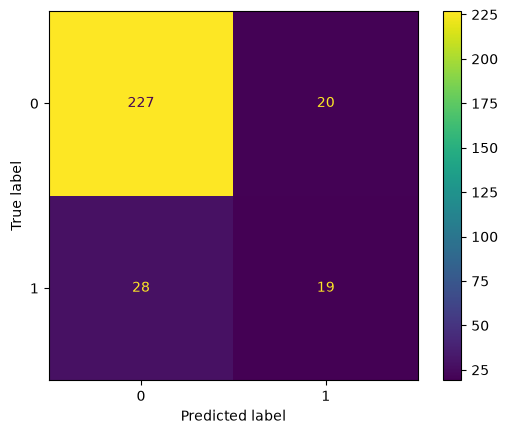

In [190]:
proba = rf.predict_proba(X_test)[:, 1]
print(f"test ROC-AUC: {roc_auc_score(y_test, proba):.3f} | PR-AUC: {average_precision_score(y_test, proba):.3f}")
print(classification_report(y_test, model.predict(X_test)))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test);

## Precision vs. Recall: a cost trade-off
With our threshold of 0.27 the model makes two kinds of errors on the 294 test employees:

| Error | Count | Measured by | Cost |
|---|---|---|---|
| **Missed leaver** | 28 | Recall: 19 of 47 leavers found = 0.40 | Employee leaves without warning |
| **False alarm** | 20 | Precision: 19 of 39 flags correct = 0.49 | Unnecessary retention conversation |

A lower threshold means fewer missed leavers but more false alarms, a higher threshold the opposite. It cannot reduce both errors at once (see curve below).

Our threshold maximises F1, which treats both errors as equally important. Which error is really more expensive is a business decision that we leave to management.

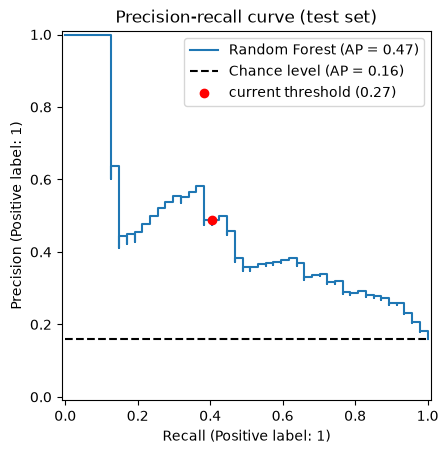

In [191]:
# precision-recall curve over all thresholds, with our chosen threshold marked
y_pred = model.predict(X_test)
disp = PrecisionRecallDisplay.from_predictions(
    y_test, proba, name="Random Forest", plot_chance_level=True
)
disp.ax_.scatter(
    recall_score(y_test, y_pred), precision_score(y_test, y_pred),
    color="red", zorder=3, label=f"current threshold ({model.best_threshold_:.2f})",
)
disp.ax_.set_title("Precision-recall curve (test set)")
disp.ax_.legend();